In [7]:
# ── Imports ────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.neighbors import NearestNeighbors

plt.rcParams["figure.dpi"] = 100
np.random.seed(42)
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [8]:
# ── Load encoded dataset ───────────────────────────────────────────────────
from pathlib import Path

ENCODED_DATA_PATH = Path.cwd() / "data" / "spotify_encoded.csv"
if not ENCODED_DATA_PATH.exists():
    ENCODED_DATA_PATH = Path.cwd().parent / "data" / "spotify_encoded.csv"
if not ENCODED_DATA_PATH.exists():
    ENCODED_DATA_PATH = Path.cwd() / "backend" / "data" / "spotify_encoded.csv"
df = pd.read_csv(ENCODED_DATA_PATH)
print("Dataset shape:", df.shape)

# Audio feature columns (numeric, after feature engineering transforms)
audio_features = [
    "popularity", "duration_ms", "explicit", "danceability", "energy",
    "key", "loudness", "mode", "speechiness", "acousticness",
    "instrumentalness", "liveness", "valence", "tempo", "time_signature"
]

X = df[audio_features].dropna().values
feature_names = audio_features
print(f"Feature matrix : {X.shape[0]:,} samples  x  {X.shape[1]} features")
df[audio_features].describe().round(3)

Dataset shape: (112329, 129)
Feature matrix : 112,329 samples  x  15 features


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000,112329.000
mean,33.354,12.267,0.086,0.569,0.288,5.313,2.102,0.638,0.077,0.242,0.115,0.183,0.476,122.451,0.715
std,22.315,0.376,0.280,0.172,0.179,3.561,0.474,0.481,0.081,0.238,0.223,0.138,0.259,29.618,0.143
min,0.000,9.668,0.000,0.051,0.000,0.000,0.000,0.000,0.022,0.000,0.000,0.009,0.000,30.200,0.000
25%,17.000,12.071,0.000,0.458,0.136,2.000,1.791,0.000,0.035,0.016,0.000,0.093,0.262,99.762,0.693
50%,35.000,12.270,0.000,0.582,0.272,5.000,2.076,1.000,0.048,0.154,0.000,0.124,0.466,122.058,0.693
75%,50.000,12.475,0.000,0.695,0.421,8.000,2.392,1.000,0.081,0.463,0.044,0.241,0.684,140.105,0.693
max,100.000,15.471,1.000,0.985,0.693,11.000,3.863,1.000,0.675,0.691,0.693,0.693,0.995,243.372,1.099


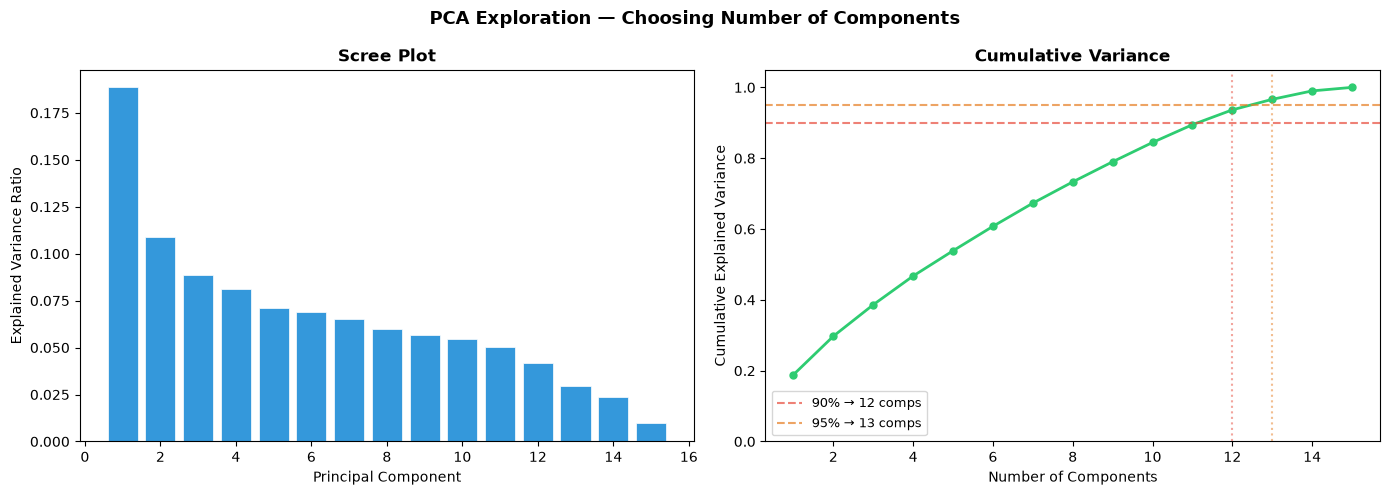

  Components for 85% variance: 11
  Components for 90% variance: 12
  Components for 95% variance: 13


In [9]:
# ── PCA Exploration — pick n_components ───────────────────────────────────
_scaler = StandardScaler()
_X_sc   = _scaler.fit_transform(X)
_pca    = PCA(random_state=42).fit(_X_sc)
cumvar  = np.cumsum(_pca.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].bar(range(1, len(_pca.explained_variance_ratio_) + 1),
            _pca.explained_variance_ratio_,
            color="#3498db", edgecolor="white", linewidth=0.5)
axes[0].set_xlabel("Principal Component")
axes[0].set_ylabel("Explained Variance Ratio")
axes[0].set_title("Scree Plot", fontweight="bold")

# Cumulative variance
axes[1].plot(range(1, len(cumvar) + 1), cumvar, "o-", color="#2ecc71", linewidth=2, markersize=5)
for threshold, color, label in [(0.90, "#e74c3c", "90%"), (0.95, "#e67e22", "95%")]:
    n = int(np.argmax(cumvar >= threshold)) + 1
    axes[1].axhline(threshold, linestyle="--", color=color, alpha=0.7, label=f"{label} → {n} comps")
    axes[1].axvline(n, linestyle=":", color=color, alpha=0.5)
axes[1].set_xlabel("Number of Components")
axes[1].set_ylabel("Cumulative Explained Variance")
axes[1].set_title("Cumulative Variance", fontweight="bold")
axes[1].legend(fontsize=9)
axes[1].set_ylim(0, 1.05)

plt.suptitle("PCA Exploration — Choosing Number of Components", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

for t in [0.85, 0.90, 0.95]:
    print(f"  Components for {int(t*100)}% variance: {int(np.argmax(cumvar >= t)) + 1}")

In [10]:
# ══════════════════════════════════════════════════════════════════════════
#   ClusteringPipeline  — accepts models as a dict
# ══════════════════════════════════════════════════════════════════════════
class ClusteringPipeline:
    """
    Unified training & evaluation pipeline for unsupervised models.

    Parameters
    ----------
    models : dict
        {name: sklearn_model}.  Include a PCA instance to use it for
        dimensionality reduction before clustering; all other entries are
        treated as clustering algorithms.
    sample_size : int
        Maximum samples used for expensive metrics (silhouette). Default 10 000.
    random_state : int
        Random seed. Default 42.
    """

    def __init__(self, models: dict, sample_size: int = 10_000, random_state: int = 42):
        self.random_state  = random_state
        self.sample_size   = sample_size
        self.scaler        = StandardScaler()

        # ── Separate PCA from clustering models ───────────────────────────
        self.pca = None
        self.clustering_models = {}
        for name, model in models.items():
            if isinstance(model, PCA):
                self.pca = model
            else:
                self.clustering_models[name] = model

        if self.pca is None:          # fallback: 90 % variance
            self.pca = PCA(n_components=0.90, random_state=random_state)

        # ── Storage ───────────────────────────────────────────────────────
        self.X_original_    = None
        self.X_scaled_      = None
        self.X_pca_         = None
        self.feature_names_ = None
        self.labels_        = {}
        self.metrics_       = None
        self.profiles_      = {}

    # ── fit ───────────────────────────────────────────────────────────────
    def fit(self, X: np.ndarray, feature_names: list = None):
        """Scale → PCA → fit all clustering models."""
        self.X_original_    = X.copy()
        self.feature_names_ = feature_names or [f"f{i}" for i in range(X.shape[1])]

        # 1. Scale
        self.X_scaled_ = self.scaler.fit_transform(X)

        # 2. PCA
        self.X_pca_ = self.pca.fit_transform(self.X_scaled_)
        print(f"[PCA]  {X.shape[1]}D → {self.X_pca_.shape[1]}D  "
              f"| variance explained: {self.pca.explained_variance_ratio_.sum():.3%}")

        # 3. Fit clustering models
        for name, model in self.clustering_models.items():
            print(f"[Fit]  {name} ...", end=" ", flush=True)
            model.fit(self.X_pca_)
            self.labels_[name] = (
                model.labels_ if hasattr(model, "labels_")
                else model.predict(self.X_pca_)
            )
            n_cl = len(set(self.labels_[name]) - {-1})
            n_noise = int((self.labels_[name] == -1).sum())
            print(f"Done  |  clusters: {n_cl}  |  noise: {n_noise:,}")

        return self

    # ── evaluate ──────────────────────────────────────────────────────────
    def evaluate(self) -> pd.DataFrame:
        """Compute silhouette score, inertia, cluster/noise counts."""
        np.random.seed(self.random_state)
        rows = []

        for name, labels in self.labels_.items():
            model  = self.clustering_models[name]
            mask   = labels != -1
            n_cl   = len(set(labels[mask]))
            n_noise= int((~mask).sum())

            # Silhouette score (subsample for speed)
            sil = None
            if n_cl > 1 and mask.sum() > n_cl:
                Xv, lv = self.X_pca_[mask], labels[mask]
                if len(Xv) > self.sample_size:
                    idx = np.random.choice(len(Xv), self.sample_size, replace=False)
                    Xv, lv = Xv[idx], lv[idx]
                sil = silhouette_score(Xv, lv)

            # Inertia (KMeans only)
            inertia = getattr(model, "inertia_", None)

            rows.append({
                "Model"             : name,
                "Clusters"          : n_cl,
                "Noise Points"      : n_noise,
                "Silhouette Score ↑": round(sil, 4) if sil is not None else "—",
                "Inertia ↓"         : f"{inertia:,.0f}" if inertia else "—"
            })

        self.metrics_ = pd.DataFrame(rows).set_index("Model")
        return self.metrics_

    # ── profile ───────────────────────────────────────────────────────────
    def profile(self) -> dict:
        """Per-cluster mean of z-scored features (excludes noise points)."""
        for name, labels in self.labels_.items():
            tmp = pd.DataFrame(self.X_scaled_, columns=self.feature_names_)
            tmp["_cluster"] = labels
            valid = tmp[tmp["_cluster"] != -1]
            self.profiles_[name] = valid.groupby("_cluster")[self.feature_names_].mean()
        return self.profiles_

    # ── plot: silhouette ──────────────────────────────────────────────────
    def plot_silhouette(self, model_name: str):
        labels = self.labels_[model_name]
        mask   = labels != -1
        Xv, lv = self.X_pca_[mask], labels[mask]
        np.random.seed(self.random_state)
        if len(Xv) > self.sample_size:
            idx = np.random.choice(len(Xv), self.sample_size, replace=False)
            Xv, lv = Xv[idx], lv[idx]

        sil_vals = silhouette_samples(Xv, lv)
        avg_sil  = sil_vals.mean()
        clusters = sorted(set(lv))
        colors   = sns.color_palette("tab10", len(clusters))

        fig, ax = plt.subplots(figsize=(10, 6))
        y_lower = 10
        for i, c in enumerate(clusters):
            cv   = np.sort(sil_vals[lv == c])
            y_up = y_lower + len(cv)
            ax.fill_betweenx(np.arange(y_lower, y_up), 0, cv,
                             color=colors[i], alpha=0.85, label=f"Cluster {c}")
            y_lower = y_up + 10

        ax.axvline(avg_sil, linestyle="--", color="red", linewidth=1.5,
                   label=f"Avg = {avg_sil:.4f}")
        ax.set_xlabel("Silhouette Coefficient")
        ax.set_title(f"Silhouette Plot — {model_name}", fontsize=13, fontweight="bold")
        ax.legend(fontsize=8, loc="upper right")
        plt.tight_layout()
        plt.show()

    # ── plot: PCA scatter ─────────────────────────────────────────────────
    def plot_pca_scatter(self):
        n   = len(self.clustering_models)
        fig, axes = plt.subplots(1, n, figsize=(7 * n, 6))
        if n == 1:
            axes = [axes]

        # Sample for scatter speed
        np.random.seed(self.random_state)
        idx = np.random.choice(len(self.X_pca_), min(20_000, len(self.X_pca_)), replace=False)

        for ax, (name, labels) in zip(axes, self.labels_.items()):
            sc = ax.scatter(self.X_pca_[idx, 0], self.X_pca_[idx, 1],
                            c=labels[idx], cmap="tab10", s=3, alpha=0.4)
            plt.colorbar(sc, ax=ax, label="Cluster")
            ax.set_title(f"{name}  (PC1 vs PC2)", fontweight="bold")
            ax.set_xlabel("PC 1")
            ax.set_ylabel("PC 2")

        plt.suptitle("Cluster Assignments in PCA Space", fontsize=14, fontweight="bold")
        plt.tight_layout()
        plt.show()

    # ── plot: cluster profiles ────────────────────────────────────────────
    def plot_profiles(self):
        if not self.profiles_:
            self.profile()
        n   = len(self.profiles_)
        fig, axes = plt.subplots(1, n, figsize=(8 * n, 5))
        if n == 1:
            axes = [axes]

        for ax, (name, prof) in zip(axes, self.profiles_.items()):
            normed = (prof - prof.mean()) / (prof.std() + 1e-9)
            sns.heatmap(normed.T, ax=ax, cmap="RdYlGn", center=0,
                        linewidths=0.4, annot=len(prof) <= 8, fmt=".2f", cbar=True)
            ax.set_title(f"{name}", fontweight="bold")
            ax.set_xlabel("Cluster")
            ax.set_ylabel("")

        plt.suptitle("Cluster Profiles — z-scored Mean Feature Values",
                     fontsize=13, fontweight="bold")
        plt.tight_layout()
        plt.show()

print("ClusteringPipeline class defined.")

ClusteringPipeline class defined.


In [11]:
# ── Models Dictionary ──────────────────────────────────────────────────────
# Add or remove models here — the pipeline adapts automatically.
# Include a PCA instance to configure dimensionality reduction.

models = {
    # Dimensionality Reduction (applied before all clustering models)
    "PCA"         : PCA(n_components=0.90, random_state=42),

    # Clustering models
    "KMeans"      : KMeans(n_clusters=5, random_state=42, n_init=10),
    "DBSCAN"      : DBSCAN(eps=1.5, min_samples=50)
}

for name, model in models.items():
    print(f"  {name:15s}: {model}")

  PCA            : PCA(n_components=0.9, random_state=42)
  KMeans         : KMeans(n_clusters=5, n_init=10, random_state=42)
  DBSCAN         : DBSCAN(eps=1.5, min_samples=50)


In [12]:
# ── Fit the Pipeline ───────────────────────────────────────────────────────
pipeline = ClusteringPipeline(models=models, sample_size=10_000, random_state=42)
pipeline.fit(X, feature_names=feature_names)

[PCA]  15D → 12D  | variance explained: 93.652%
[Fit]  KMeans ... Done  |  clusters: 5  |  noise: 0
[Fit]  DBSCAN ... Done  |  clusters: 10  |  noise: 24,959


In [13]:
# ── Evaluation Metrics ─────────────────────────────────────────────────────
metrics = pipeline.evaluate()
print("=" * 60)
print("         CLUSTERING PIPELINE — EVALUATION METRICS")
print("=" * 60)
display(metrics)

         CLUSTERING PIPELINE — EVALUATION METRICS


,Clusters,Noise Points,Silhouette Score ↑,Inertia ↓
Model,,,,
KMeans,5,0,0.112,"1,105,593"
DBSCAN,10,24959,0.065,—


Running KMeans for k = 2 … 12 ...
  k= 2  inertia=   1,362,950  silhouette=0.1489
  k= 3  inertia=   1,244,290  silhouette=0.1683
  k= 4  inertia=   1,161,997  silhouette=0.1120
  k= 5  inertia=   1,105,593  silhouette=0.1120
  k= 6  inertia=   1,057,355  silhouette=0.1063
  k= 7  inertia=   1,010,145  silhouette=0.1210
  k= 8  inertia=     970,741  silhouette=0.1146
  k= 9  inertia=     931,343  silhouette=0.1211
  k=10  inertia=     897,000  silhouette=0.1249
  k=11  inertia=     874,785  silhouette=0.1129
  k=12  inertia=     856,992  silhouette=0.1102


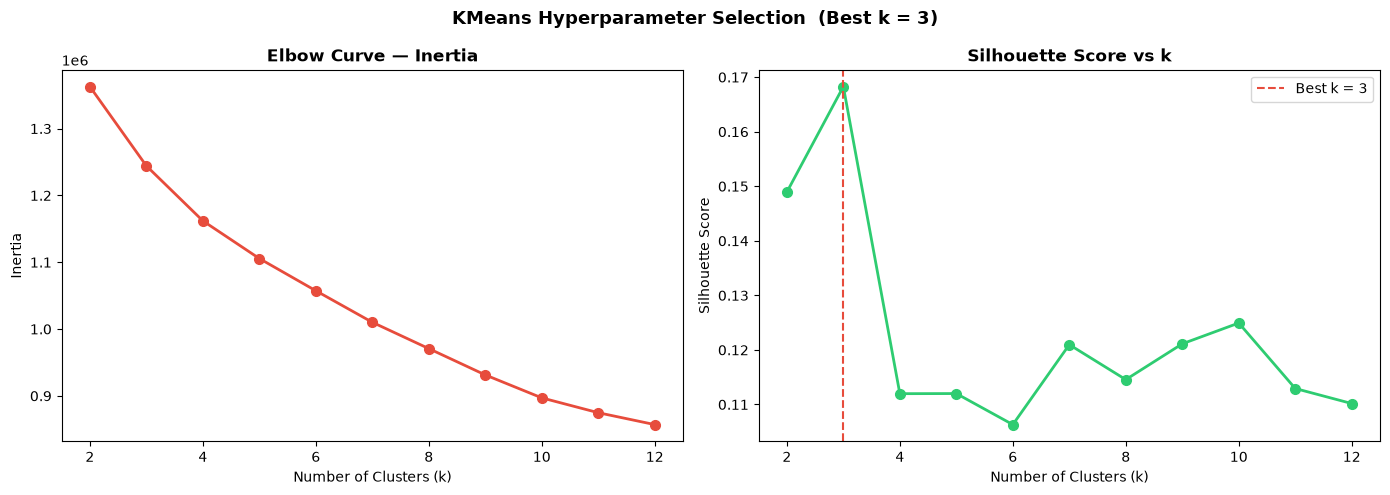


Recommended k = 3  (highest silhouette score = 0.1683)


In [14]:
# ── KMeans Elbow + Silhouette vs k ────────────────────────────────────────
K_range    = range(2, 13)
inertias   = []
sil_scores = []
np.random.seed(42)
sample_idx = np.random.choice(len(pipeline.X_pca_), 10_000, replace=False)

print("Running KMeans for k = 2 … 12 ...")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=5).fit(pipeline.X_pca_)
    inertias.append(km.inertia_)
    s = silhouette_score(pipeline.X_pca_[sample_idx], km.labels_[sample_idx])
    sil_scores.append(s)
    print(f"  k={k:2d}  inertia={km.inertia_:>12,.0f}  silhouette={s:.4f}")

best_k = list(K_range)[int(np.argmax(sil_scores))]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(K_range), inertias, "o-", color="#e74c3c", linewidth=2, markersize=7)
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Curve — Inertia", fontweight="bold")
axes[0].xaxis.set_major_locator(plt.MaxNLocator(integer=True))

axes[1].plot(list(K_range), sil_scores, "o-", color="#2ecc71", linewidth=2, markersize=7)
axes[1].axvline(best_k, linestyle="--", color="#e74c3c", label=f"Best k = {best_k}")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].set_title("Silhouette Score vs k", fontweight="bold")
axes[1].legend()
axes[1].xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.suptitle(f"KMeans Hyperparameter Selection  (Best k = {best_k})",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()
print(f"\nRecommended k = {best_k}  (highest silhouette score = {max(sil_scores):.4f})")


Silhouette plot for KMeans  (5 clusters, 112,329 valid points)


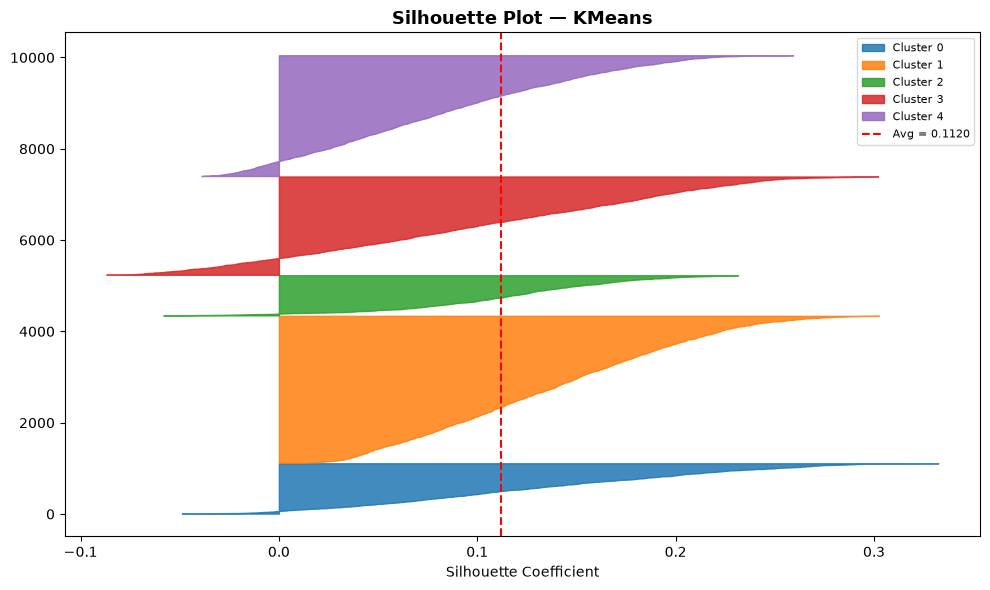


Silhouette plot for DBSCAN  (10 clusters, 87,370 valid points)


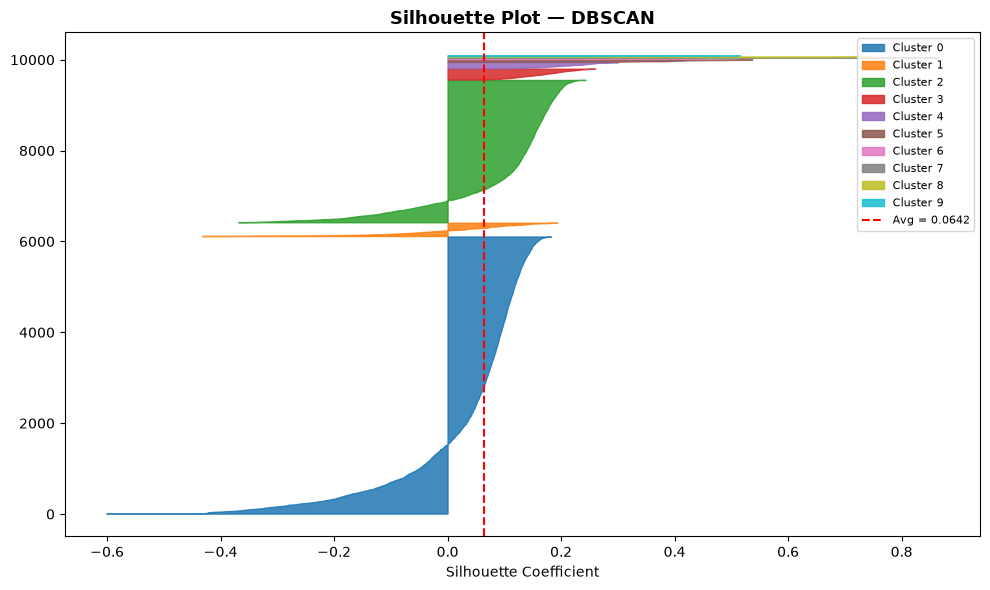

In [15]:
# ── Silhouette Analysis — one plot per clustering model ───────────────────
for name in pipeline.clustering_models:
    labels  = pipeline.labels_[name]
    n_valid = int((labels != -1).sum())
    n_cl    = len(set(labels) - {-1})
    if n_cl > 1:
        print(f"\nSilhouette plot for {name}  ({n_cl} clusters, {n_valid:,} valid points)")
        pipeline.plot_silhouette(name)
    else:
        print(f"[{name}] Skipping silhouette — only {n_cl} cluster found.")

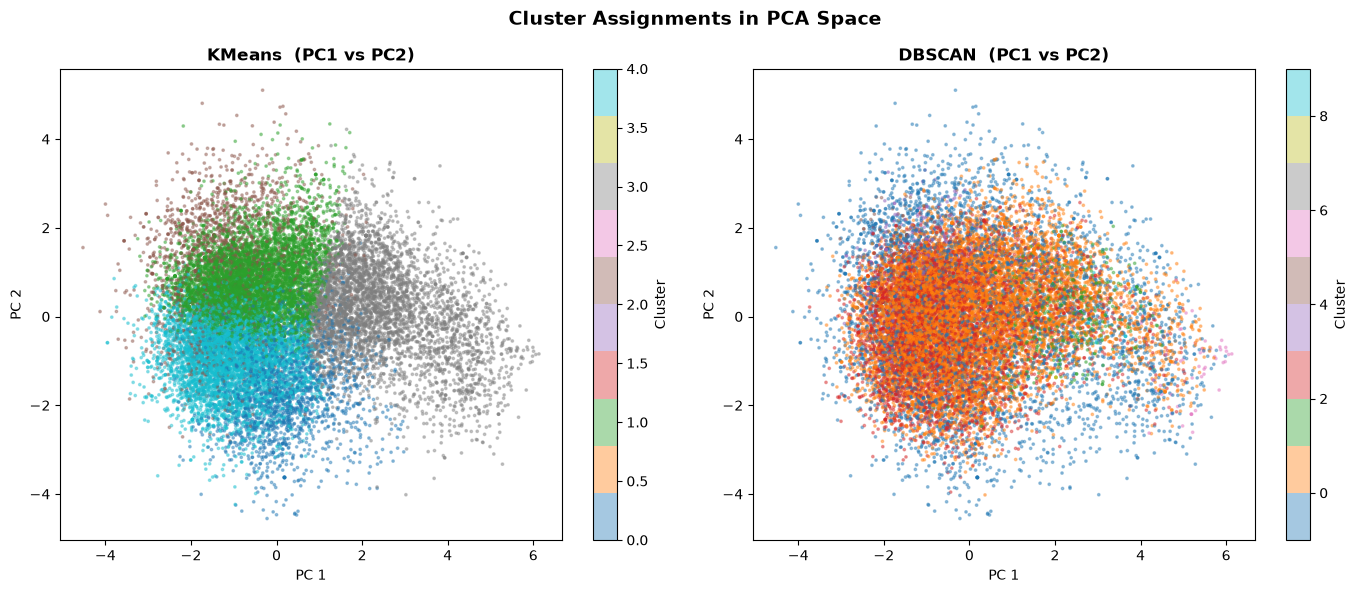

In [16]:
# ── PCA 2D Scatter — clusters visualised in PC1 vs PC2 space ─────────────
pipeline.plot_pca_scatter()

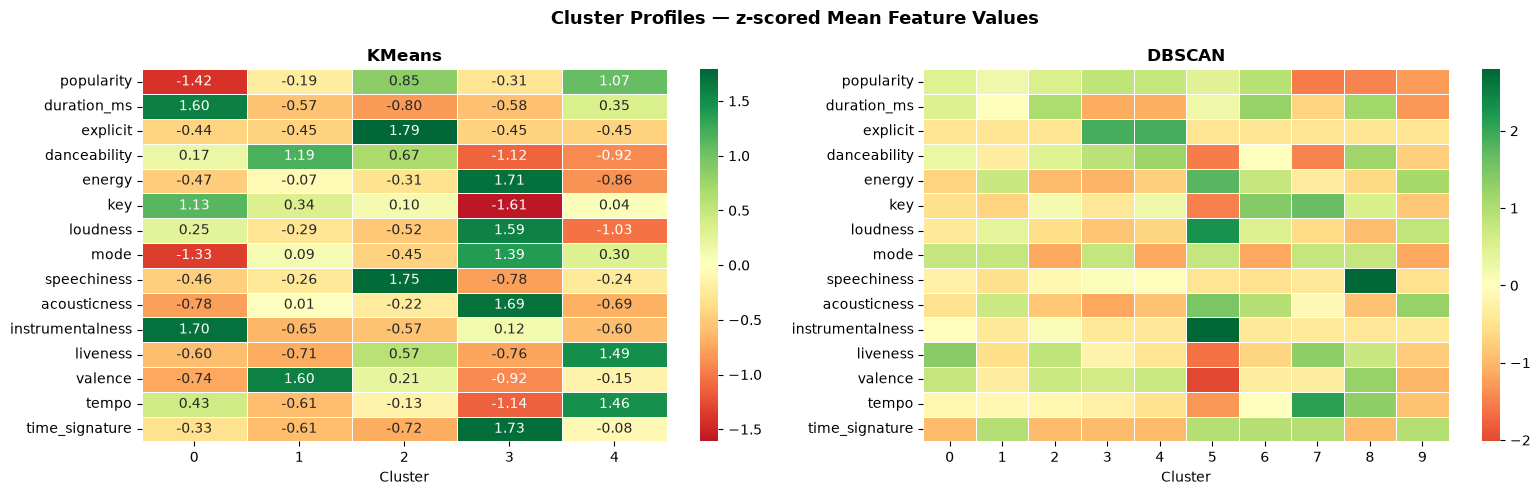


           CLUSTER SIZE DISTRIBUTION

  KMeans:
    Cluster 0   : 11,566  ( 10.3%)  ████
    Cluster 1   : 37,049  ( 33.0%)  █████████████
    Cluster 2   :  9,806  (  8.7%)  ███
    Cluster 3   : 24,706  ( 22.0%)  ████████
    Cluster 4   : 29,202  ( 26.0%)  ██████████

  DBSCAN:
    Noise       : 24,959  ( 22.2%)  ████████
    Cluster 0   : 53,085  ( 47.3%)  ██████████████████
    Cluster 1   :  2,529  (  2.3%)  
    Cluster 2   : 27,801  ( 24.7%)  █████████
    Cluster 3   :  1,958  (  1.7%)  
    Cluster 4   :  1,194  (  1.1%)  
    Cluster 5   :    331  (  0.3%)  
    Cluster 6   :    126  (  0.1%)  
    Cluster 7   :     90  (  0.1%)  
    Cluster 8   :     93  (  0.1%)  
    Cluster 9   :    163  (  0.1%)  

     TOP DISTINGUISHING FEATURES PER CLUSTER

  [KMeans]
    Cluster 0: instrumentalness=+1.70, duration_ms=+1.60, popularity=-1.42
    Cluster 1: valence=+1.60, danceability=+1.19, liveness=-0.71
    Cluster 2: explicit=+1.79, speechiness=+1.75, popularity=+0.85
    Cluste

In [17]:
# ── Cluster Profiling ─────────────────────────────────────────────────────
profiles = pipeline.profile()
pipeline.plot_profiles()

# Cluster size summary
print("\n" + "=" * 55)
print("           CLUSTER SIZE DISTRIBUTION")
print("=" * 55)
for name, labels in pipeline.labels_.items():
    unique, counts = np.unique(labels, return_counts=True)
    print(f"\n  {name}:")
    for c, cnt in zip(unique, counts):
        tag = "Noise" if c == -1 else f"Cluster {c}"
        bar = "█" * int(cnt / len(labels) * 40)
        print(f"    {tag:12s}: {cnt:6,}  ({cnt/len(labels)*100:5.1f}%)  {bar}")

# Top distinguishing features per cluster (highest abs z-score)
print("\n" + "=" * 55)
print("     TOP DISTINGUISHING FEATURES PER CLUSTER")
print("=" * 55)
for name, prof in profiles.items():
    print(f"\n  [{name}]")
    normed = (prof - prof.mean()) / (prof.std() + 1e-9)
    for cl in normed.index:
        top3 = normed.loc[cl].abs().nlargest(3).index.tolist()
        vals = [f"{feat}={normed.loc[cl, feat]:+.2f}" for feat in top3]
        print(f"    Cluster {cl}: {', '.join(vals)}")

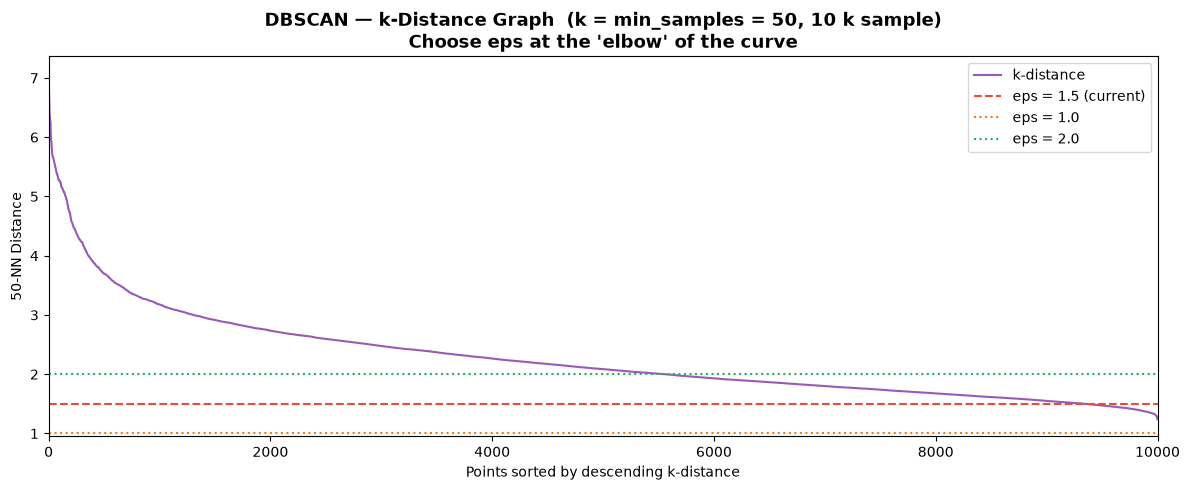

In [18]:
# ── DBSCAN — k-Distance Plot for eps selection ────────────────────────────
MIN_SAMPLES = 50

np.random.seed(42)
kd_idx = np.random.choice(len(pipeline.X_pca_), 10_000, replace=False)
X_kd   = pipeline.X_pca_[kd_idx]

nbrs       = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X_kd)
distances  = nbrs.kneighbors(X_kd)[0]
k_dists    = np.sort(distances[:, -1])[::-1]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(k_dists, color="#9b59b6", linewidth=1.5, label="k-distance")
ax.axhline(1.5, linestyle="--", color="#e74c3c",  linewidth=1.5, label="eps = 1.5 (current)")
ax.axhline(1.0, linestyle=":",  color="#e67e22",  linewidth=1.5, label="eps = 1.0")
ax.axhline(2.0, linestyle=":",  color="#27ae60",  linewidth=1.5, label="eps = 2.0")
ax.set_xlabel("Points sorted by descending k-distance")
ax.set_ylabel(f"{MIN_SAMPLES}-NN Distance")
ax.set_title(f"DBSCAN — k-Distance Graph  (k = min_samples = {MIN_SAMPLES}, 10 k sample)\n"
             "Choose eps at the 'elbow' of the curve",
             fontsize=13, fontweight="bold")
ax.legend()
ax.set_xlim(0, len(k_dists))
plt.tight_layout()
plt.show()

In [19]:
# ── Final Summary Table ────────────────────────────────────────────────────
print("\n" + "=" * 62)
print("       CLUSTERING PIPELINE — FINAL RESULTS SUMMARY")
print("=" * 62)
display(
    metrics.style
    .set_caption("Model Comparison (↑ = higher is better, ↓ = lower is better)")
    .set_table_styles([{
        "selector": "caption",
        "props": [("font-size", "13px"), ("font-weight", "bold"), ("text-align", "left")]
    }])
)

# PCA summary
print(f"\nPCA Summary:")
print(f"  Input dimensions  : {X.shape[1]}")
print(f"  PCA components    : {pipeline.X_pca_.shape[1]}")
print(f"  Variance retained : {pipeline.pca.explained_variance_ratio_.sum():.3%}")

# Best model by silhouette
sil_vals = {
    name: row["Silhouette Score ↑"]
    for name, row in metrics.iterrows()
    if row["Silhouette Score ↑"] != "—"
}
if sil_vals:
    best = max(sil_vals, key=lambda k: float(sil_vals[k]))
    print(f"\nBest silhouette score : {best}  ({sil_vals[best]})")


       CLUSTERING PIPELINE — FINAL RESULTS SUMMARY


,Clusters,Noise Points,Silhouette Score ↑,Inertia ↓
Model,,,,
KMeans,5,0,0.112000,"1,105,593"
DBSCAN,10,24959,0.065000,—



PCA Summary:
  Input dimensions  : 15
  PCA components    : 12
  Variance retained : 93.652%

Best silhouette score : KMeans  (0.112)
